In [1]:
# import libraries

import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics.pairwise import cosine_similarity


In [2]:
# Load embeddings and metadata
with open(
    "women_product_embeddings_v2.pkl",
    "rb"
) as f:
    recommendation_data = pickle.load(f)

embeddings = recommendation_data["embeddings"]
metadata = recommendation_data["metadata"]

print("Embeddings shape:", embeddings.shape)
print("Metadata shape:", metadata.shape)

Embeddings shape: (18630, 1280)
Metadata shape: (18630, 19)


In [3]:
# Verify alignment
print(
    "Number of embeddings:",
    len(embeddings)
)

print(
    "Number of metadata records:",
    len(metadata)
)

print(
    "Embedding and metadata aligned:",
    len(embeddings) == len(metadata)
)

Number of embeddings: 18630
Number of metadata records: 18630
Embedding and metadata aligned: True


In [19]:
# Embedding pickle
print("Metadata columns:")
print(metadata.columns.tolist())

print("\nMetadata shape:")
print(metadata.shape)

Metadata columns:
['id', 'productDisplayName', 'brandName', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'filename', 'imageURL', 'masterCategoryName', 'subCategoryName', 'articleTypeName', 'modeling_category', 'image_path', 'image_exists']

Metadata shape:
(18630, 19)


In [20]:
import pandas as pd

label_mapping = pd.read_csv(
    "article_type_label_mapping_v2.csv"
)

print("Label mapping columns:")
print(label_mapping.columns.tolist())

print("\nLabel mapping shape:")
print(label_mapping.shape)

print("\nFirst 10 rows:")
display(label_mapping.head(10))

Label mapping columns:
['label', 'articleTypeName']

Label mapping shape:
(54, 2)

First 10 rows:


,label,articleTypeName
0,0,Bangle
1,1,Belts
2,2,Bra
3,3,Bracelet
4,4,Briefs
5,5,Capris
6,6,Casual Shoes
7,7,Clutches
8,8,Deodorant
9,9,Dresses


In [21]:
print("Number of classes:", len(label_mapping))
print(label_mapping)

Number of classes: 54
    label        articleTypeName
0       0                 Bangle
1       1                  Belts
2       2                    Bra
3       3               Bracelet
4       4                 Briefs
5       5                 Capris
6       6           Casual Shoes
7       7               Clutches
8       8              Deodorant
9       9                Dresses
10     10                Dupatta
11     11               Earrings
12     12      Face Moisturisers
13     13                  Flats
14     14             Flip Flops
15     15  Foundation and Primer
16     16               Handbags
17     17                  Heels
18     18  Highlighter and Blush
19     19                Jackets
20     20                  Jeans
21     21          Jewellery Set
22     22     Kajal and Eyeliner
23     23             Kurta Sets
24     24                 Kurtas
25     25                 Kurtis
26     26               Leggings
27     27              Lip Gloss
28     28            

In [23]:
# label mapping
print("Label mapping columns:")
print(label_mapping.columns.tolist())

print("\nLabel mapping:")
print(label_mapping.head())

Label mapping columns:
['label', 'articleTypeName']

Label mapping:
   label articleTypeName
0      0          Bangle
1      1           Belts
2      2             Bra
3      3        Bracelet
4      4          Briefs


<!-- Cosine Similarity -->

In [4]:
# Create recommendation function
def recommend_similar_products(
    query_index,
    embeddings,
    metadata,
    top_n=5
):
    # Get query product's article type
    query_article_type = metadata.iloc[
        query_index
    ]["articleTypeName"]

    # Filter products to the same article type
    category_mask = (
        metadata["articleTypeName"]
        == query_article_type
    )

    candidate_indices = np.where(
        category_mask.values
    )[0]

    # Get query embedding
    query_embedding = embeddings[
        query_index
    ].reshape(1, -1)

    # Calculate cosine similarity only
    # within the same article type
    candidate_embeddings = embeddings[
        candidate_indices
    ]

    similarity_scores = cosine_similarity(
        query_embedding,
        candidate_embeddings
    )[0]

    # Remove the query product itself
    query_position = np.where(
        candidate_indices == query_index
    )[0]

    if len(query_position) > 0:
        similarity_scores[
            query_position[0]
        ] = -1

    # Rank by similarity
    top_positions = np.argsort(
        similarity_scores
    )[::-1][:top_n]

    top_indices = candidate_indices[
        top_positions
    ]

    # Get metadata
    recommendations = metadata.iloc[
        top_indices
    ].copy()

    # Add similarity score
    recommendations[
        "similarity_score"
    ] = similarity_scores[
        top_positions
    ]

    return recommendations

Query image
↓
1280-D embedding
↓
Compare with 18,630 embeddings
↓
Cosine similarity
↓
Sort highest → lowest
↓
Remove query product
↓
Top-N products

In [5]:
# Test the recommendation engine
query_index = 100

query_product = metadata.iloc[
    query_index
]

print("Query Product:")
print(
    "ID:",
    query_product["id"]
)

print(
    "Name:",
    query_product["productDisplayName"]
)

print(
    "Article Type:",
    query_product["articleTypeName"]
)

Query Product:
ID: 23542
Name: Police Women Pure EDT Perfume
Article Type: Perfume and Body Mist


In [6]:
# Generate Top 5
recommendations = recommend_similar_products(
    query_index=query_index,
    embeddings=embeddings,
    metadata=metadata,
    top_n=5
)

display(
    recommendations[
        [
            "id",
            "productDisplayName",
            "brandName",
            "articleTypeName",
            "baseColour",
            "similarity_score"
        ]
    ]
)

,id,productDisplayName,brandName,articleTypeName,baseColour,similarity_score
7734,43981,Police Women Pure Pour Perfume,Police,Perfume and Body Mist,Pink,0.776235
3638,44002,Police Women Pure Perfume,Police,Perfume and Body Mist,White,0.628056
1036,44003,Police Women Pure Perfume,Police,Perfume and Body Mist,White,0.626980
2088,23562,Police Pure Women Perfume,Police,Perfume and Body Mist,Cream,0.528947
409,46950,York Women Hypnose Perfume,York,Perfume and Body Mist,Red,0.521897


In [7]:
# Verify similarity scores
print(
    recommendations[
        "similarity_score"
    ].values
)

[0.77623475 0.62805593 0.6269802  0.52894676 0.52189714]


0.7762 → relatively strong visual similarity
0.6281 / 0.6270 → moderate similarity
0.5421 / 0.5413 → weaker but still among the closest products in our dataset

In [8]:
# Verify query product is excluded
print(
    "Query article type:",
    query_product["articleTypeName"]
)

print(
    "All recommendations same category:",
    all(
        recommendations["articleTypeName"]
        == query_product["articleTypeName"]
    )
)

Query article type: Perfume and Body Mist
All recommendations same category: True


validation step because otherwise the system could recommend the same product as its own most similar item.


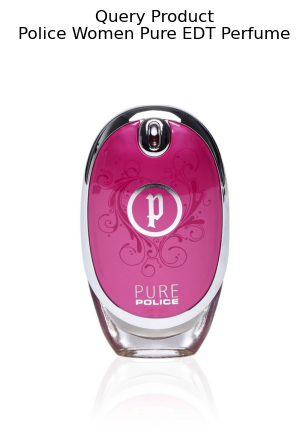

In [9]:
# Display query image
query_image = plt.imread(
    query_product["image_path"]
)

plt.figure(figsize=(5, 5))

plt.imshow(query_image)

plt.title(
    f"Query Product\n"
    f"{query_product['productDisplayName']}"
)

plt.axis("off")
plt.show()

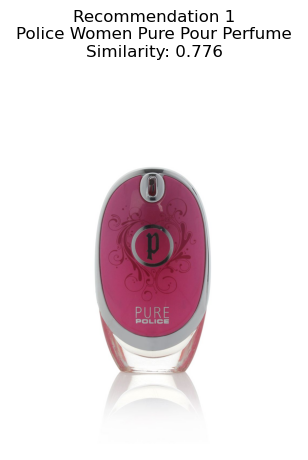

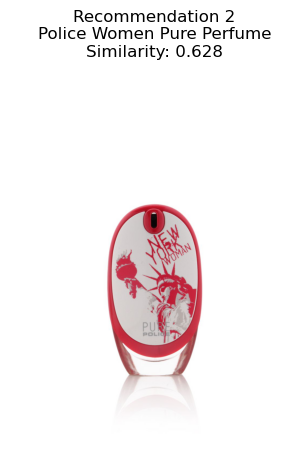

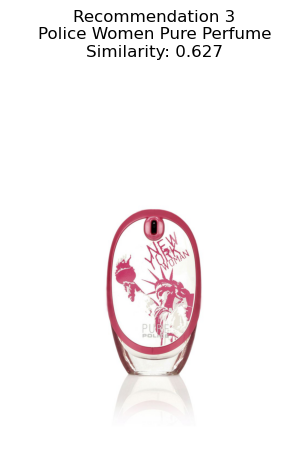

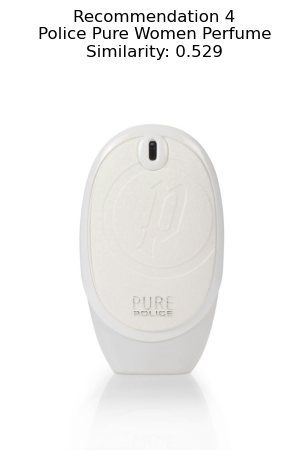

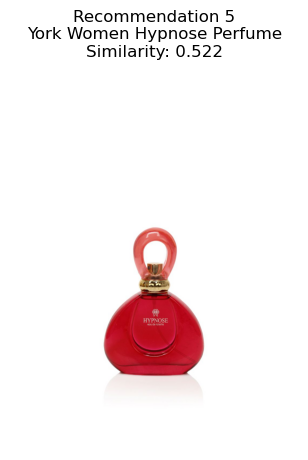

In [10]:
# Display Top-5 recommendations --> visually inspect whether the recommendations actually look similar.

for rank, (_, row) in enumerate(
    recommendations.iterrows(),
    start=1
):

    image = plt.imread(
        row["image_path"]
    )

    plt.figure(figsize=(5, 5))

    plt.imshow(image)

    plt.title(
        f"Recommendation {rank}\n"
        f"{row['productDisplayName']}\n"
        f"Similarity: "
        f"{row['similarity_score']:.3f}"
    )

    plt.axis("off")
    plt.show()

In [11]:
# Check category restriction -->Recommend visually similar products within the recognized category

print(
    "Categories in recommendation metadata:"
)

print(
    metadata["modeling_category"].value_counts()
)


Categories in recommendation metadata:
modeling_category
Women    18630
Name: count, dtype: int64


The initial similarity-based approach successfully identified visually similar products, but some recommendations belonged to different article types because the similarity calculation was based solely on visual embeddings. This motivated the integration of category-based filtering using the recognized product category.

In [27]:
print(" --Recommendation Engine Validation-- ")
print("Total products:", len(metadata))
print("Embedding dimensions:", embeddings.shape[1])
print("Recommendation method: Cosine Similarity")
print("Category filtering: Article Type")
print("Top-N:", 5)
print("Query product excluded: True")
print("Recommendation engine ready: YES")

 --Recommendation Engine Validation-- 
Total products: 18630
Embedding dimensions: 1280
Recommendation method: Cosine Similarity
Category filtering: Article Type
Top-N: 5
Query product excluded: True
Recommendation engine ready: YES


### Similarity Analysis Insight

The initial cosine-similarity approach successfully identified visually similar products. For the perfume query, the top three recommendations were visually very similar perfume products, demonstrating that the EfficientNetB0 embeddings capture meaningful visual characteristics.

However, the fourth and fifth recommendations were skincare products rather than perfumes. This indicates that visual similarity alone can retrieve products from different article types when their packaging, colour, shape, or product photography is visually similar.

Therefore, category filtering will be incorporated into the final recommendation engine so that recommendations are generated within the recognized article type while still being ranked using cosine similarity.

###  Insights

- Cosine similarity was successfully used to compare the 1,280-dimensional image embeddings.

- The recommendation system initially identified visually similar products across the Women category.

- Initial testing showed that visually similar packaging could cause products from different article types to be recommended.

- To improve recommendation relevance, an article-type filter was introduced before calculating similarity.

- After filtering, the system recommends products belonging to the same article type as the query product and ranks them using cosine similarity.

- For the perfume test case, all Top-5 recommendations were perfume products, demonstrating improved semantic relevance while maintaining visual similarity.

- The query product was excluded from the recommendation results.

### Conclusion

The final recommendation engine combines category-based filtering with cosine similarity to provide more relevant visually similar product recommendations.

In [24]:
import pickle

with open("women_product_embeddings_v2.pkl", "rb") as f:
    data = pickle.load(f)

print("Type of loaded object:", type(data))

if isinstance(data, tuple):
    print("Tuple length:", len(data))
    
    for i, item in enumerate(data):
        print(
            f"Item {i}:",
            type(item),
            getattr(item, "shape", None)
        )
else:
    print("Object:", data)

Type of loaded object: <class 'dict'>
Object: {'embeddings': array([[-0.01187502, -0.014838  , -0.00974619, ..., -0.01442036,
        -0.01186005, -0.02084357],
       [-0.00813717, -0.01573347, -0.00431449, ..., -0.01006573,
         0.00925201, -0.0161106 ],
       [ 0.02502711, -0.01090612,  0.01210812, ...,  0.01830185,
        -0.01541392, -0.01372599],
       ...,
       [-0.01421919, -0.01179964, -0.00817544, ...,  0.00791128,
        -0.01111764, -0.01035624],
       [ 0.00313099, -0.01489663, -0.00797631, ...,  0.08777393,
        -0.0088913 , -0.01672271],
       [ 0.00789517,  0.01344896,  0.00457202, ..., -0.00754146,
        -0.00840741, -0.0138235 ]], dtype=float32), 'metadata':           id                     productDisplayName       brandName gender  \
0      57896         Femella Women Off White Shorts         Femella  Women   
1      51041     Enamor Women Ivory Coloured Briefs          Enamor  Women   
2      59471                     Lucera Silver Ring          Luc

In [27]:
print("\nDetailed information:")

if isinstance(data, tuple):

    for i, item in enumerate(data):

        print(f"\n--- Item {i} ---")
        print("Type:", type(item))

        if hasattr(item, "shape"):
            print("Shape:", item.shape)

        if hasattr(item, "columns"):
            print("Columns:", item.columns.tolist())

        if isinstance(item, dict):
            print("Dictionary keys:", list(item.keys())[:10])


Detailed information:
